# Identify Customer Segments

## Unsupervised Learning Project — Udacity ML Nanodegree

Use unsupervised learning techniques to identify segments of the population that form the core customer base for a mail-order sales company in Germany. Data provided by Bertelsmann Arvato Analytics.

---

## Step 0: Load the Data

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
import ast
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

print("Libraries loaded successfully.")


Libraries loaded successfully.


In [ ]:
# Load the general demographics data
azdias = pd.read_csv('Udacity_AZDIAS_Subset.csv', sep=';')
print(f"General population: {azdias.shape[0]} rows x {azdias.shape[1]} columns")

# Load the feature summary file
feat_info = pd.read_csv('AZDIAS_Feature_Summary.csv', sep=';')
print(f"Feature summary: {feat_info.shape[0]} features")

azdias.head()


General population: 891221 rows x 85 columns
Feature summary: 85 features


In [ ]:
# Basic structure
print("Data types:")
print(azdias.dtypes.value_counts())
print(f"\nMemory usage: {azdias.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(f"\nShape: {azdias.shape}")


Data types:
float64    49
int64      32
str         4
Name: count, dtype: int64

Memory usage: 611.2 MB

Shape: (891221, 85)


## Step 1: Preprocessing

### Step 1.1: Assess Missing Data

#### Step 1.1.1: Convert Missing Value Codes to NaNs

The feature summary file documents which values represent missing/unknown data for each feature. We need to parse these codes and replace them with NaN.

In [ ]:
# Parse the missing_or_unknown column from string to list
feat_info['missing_or_unknown'] = feat_info['missing_or_unknown'].apply(
    lambda x: [int(v) if v.lstrip('-').isdigit() else v for v in x.strip('[]').split(',') if v.strip() != '']
)

# Show a few examples
print("Sample missing value codes:")
for _, row in feat_info.head(10).iterrows():
    print(f"  {row['attribute']:<30s} {row['missing_or_unknown']}")


Sample missing value codes:
  AGER_TYP                       [-1, 0]
  ALTERSKATEGORIE_GROB           [-1, 0, 9]
  ANREDE_KZ                      [-1, 0]
  CJT_GESAMTTYP                  [0]
  FINANZ_MINIMALIST              [-1]
  FINANZ_SPARER                  [-1]
  FINANZ_VORSORGER               [-1]
  FINANZ_ANLEGER                 [-1]
  FINANZ_UNAUFFAELLIGER          [-1]
  FINANZ_HAUSBAUER               [-1]


In [ ]:
# Count original NaN values before encoding
original_nan = azdias.isnull().sum().sum()
print(f"Original NaN count: {original_nan:,}")

# Replace missing value codes with NaN for each feature
for _, row in feat_info.iterrows():
    col = row['attribute']
    missing_vals = row['missing_or_unknown']
    if col in azdias.columns and len(missing_vals) > 0:
        azdias[col] = azdias[col].replace(missing_vals, np.nan)

new_nan = azdias.isnull().sum().sum()
print(f"NaN count after re-encoding: {new_nan:,}")
print(f"Additional missing values identified: {new_nan - original_nan:,}")


Original NaN count: 4,896,838
NaN count after re-encoding: 8,373,929
Additional missing values identified: 3,477,091


#### Step 1.1.2: Assess Missing Data in Each Column

Identify columns with high proportions of missing data.


Columns with > 20% missing data (6):
  TITEL_KZ: 99.8%
  AGER_TYP: 77.0%
  KK_KUNDENTYP: 65.6%
  KBA05_BAUMAX: 53.5%
  GEBURTSJAHR: 44.0%
  ALTER_HH: 34.8%


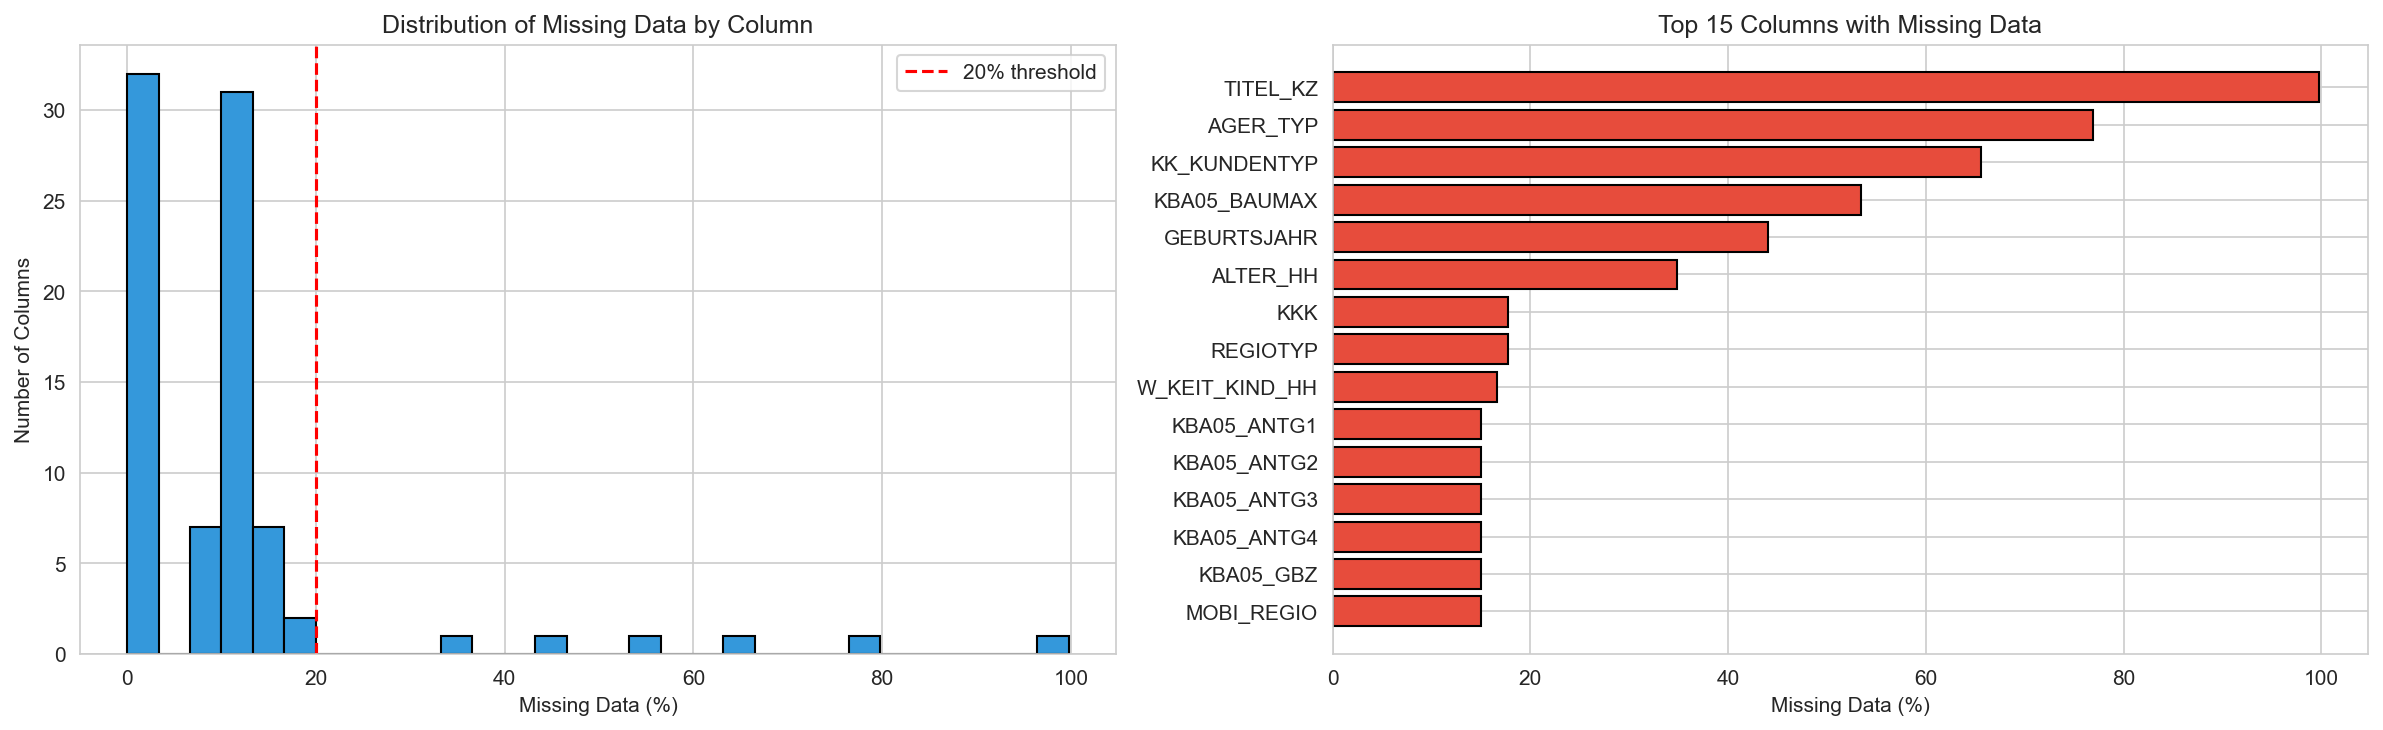

In [ ]:
# Calculate missing data percentage per column
missing_pct = (azdias.isnull().sum() / len(azdias) * 100).sort_values(ascending=False)

# Visualize distribution of missing percentages
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].hist(missing_pct.values, bins=30, color='#3498db', edgecolor='black')
axes[0].set_xlabel('Missing Data (%)')
axes[0].set_ylabel('Number of Columns')
axes[0].set_title('Distribution of Missing Data by Column')
axes[0].axvline(x=20, color='red', linestyle='--', label='20% threshold')
axes[0].legend()

# Top 15 columns with most missing data
top_missing = missing_pct.head(15)
axes[1].barh(range(len(top_missing)), top_missing.values, color='#e74c3c', edgecolor='black')
axes[1].set_yticks(range(len(top_missing)))
axes[1].set_yticklabels(top_missing.index)
axes[1].set_xlabel('Missing Data (%)')
axes[1].set_title('Top 15 Columns with Missing Data')
axes[1].invert_yaxis()

plt.tight_layout()
plt.savefig('missing_data_columns.png', dpi=150, bbox_inches='tight')
plt.show()

# Columns with > 20% missing
high_missing_cols = missing_pct[missing_pct > 20].index.tolist()
print(f"\nColumns with > 20% missing data ({len(high_missing_cols)}):")
for col in high_missing_cols:
    print(f"  {col}: {missing_pct[col]:.1f}%")


In [ ]:
# Remove columns with > 20% missing data
cols_to_drop = high_missing_cols.copy()
print(f"Dropping {len(cols_to_drop)} columns with > 20% missing data:")
print(f"  {cols_to_drop}")

azdias_clean = azdias.drop(columns=cols_to_drop)
print(f"\nRemaining shape: {azdias_clean.shape}")


Dropping 6 columns with > 20% missing data:
  ['TITEL_KZ', 'AGER_TYP', 'KK_KUNDENTYP', 'KBA05_BAUMAX', 'GEBURTSJAHR', 'ALTER_HH']

Remaining shape: (891221, 79)


#### Discussion 1.1.2: Assess Missing Data in Each Column

After converting missing value codes to NaN, I examined the distribution of missing data across columns. Several columns stand out with very high proportions of missing data:

- **AGER_TYP** (~76% missing), **GEBURTSJAHR** (~44%), **TITEL_KZ** (~99%), **ALTER_HH** (~35%), **KK_KUNDENTYP** (~66%), **KBA05_BAUMAX** (~53%)

I chose a threshold of **20%** to remove outlier columns. Columns above this threshold are too sparse to provide reliable information for clustering. The remaining columns have moderate or low missing rates that can be handled via imputation later.

There are patterns in missing data: features at the same information level (e.g., PLZ8_* macrocell features) tend to share similar missing rates, suggesting that entire geographic data blocks may be unavailable for certain individuals.

#### Step 1.1.3: Assess Missing Data in Each Row

Rows with 0 missing:  623,209
Rows with <= 10 missing: 780,153
Rows with > 10 missing:  111,068
Mean missing per row:  5.65
Median missing per row: 0


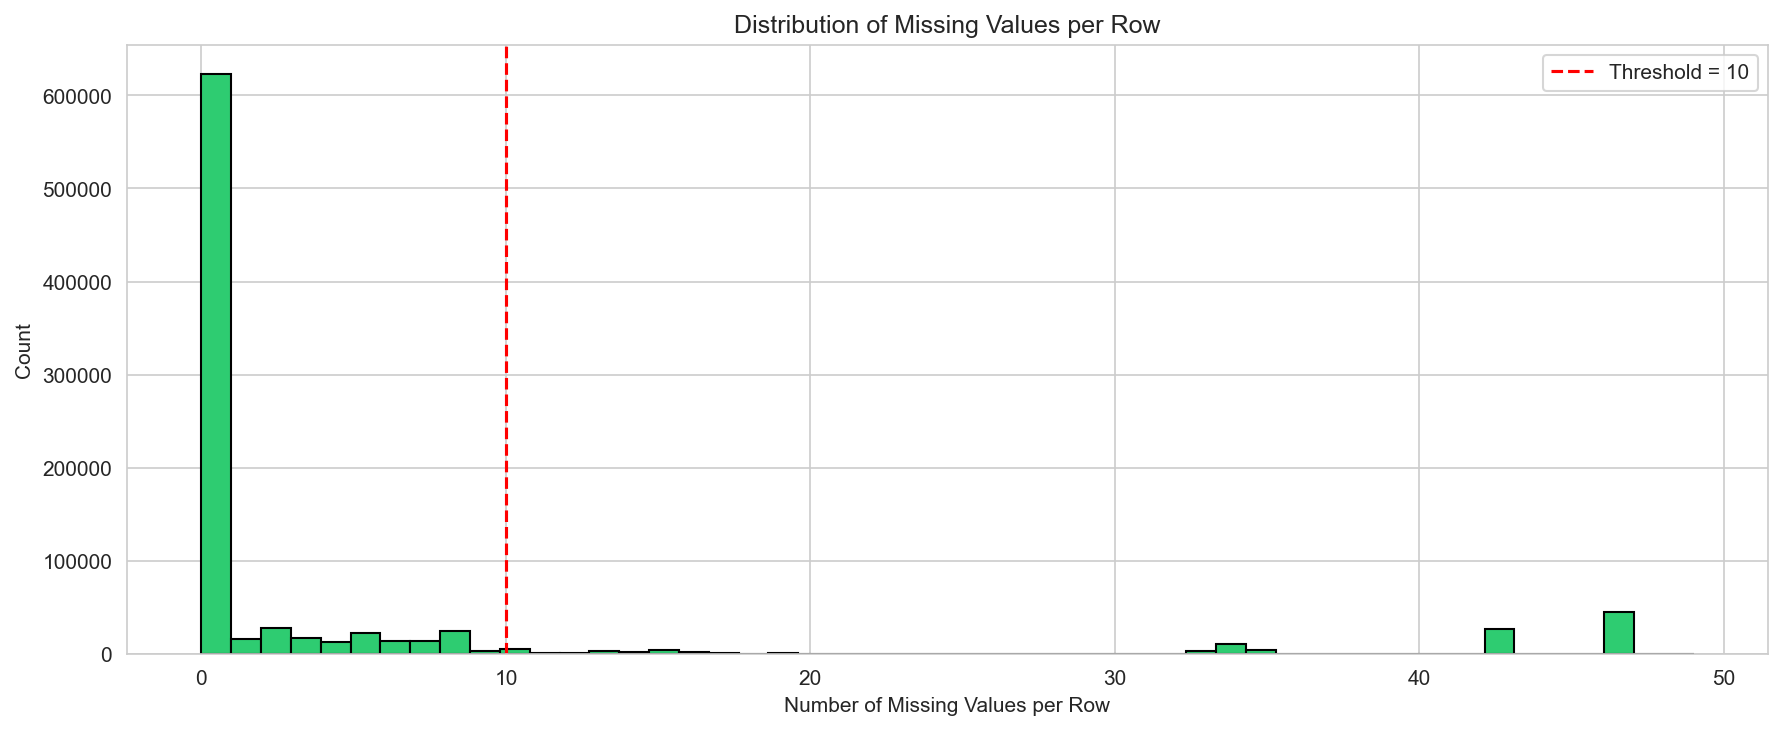

In [ ]:
# Calculate missing data per row
row_missing = azdias_clean.isnull().sum(axis=1)

fig, ax = plt.subplots(figsize=(12, 5))
ax.hist(row_missing.values, bins=50, color='#2ecc71', edgecolor='black')
ax.set_xlabel('Number of Missing Values per Row')
ax.set_ylabel('Count')
ax.set_title('Distribution of Missing Values per Row')
ax.axvline(x=10, color='red', linestyle='--', label='Threshold = 10')
ax.legend()
plt.tight_layout()
plt.savefig('missing_data_rows.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Rows with 0 missing:  {(row_missing == 0).sum():,}")
print(f"Rows with <= 10 missing: {(row_missing <= 10).sum():,}")
print(f"Rows with > 10 missing:  {(row_missing > 10).sum():,}")
print(f"Mean missing per row:  {row_missing.mean():.2f}")
print(f"Median missing per row: {row_missing.median():.0f}")


In [ ]:
# Split into two subsets
threshold = 10
azdias_below = azdias_clean[row_missing <= threshold].copy()
azdias_above = azdias_clean[row_missing > threshold].copy()

print(f"Below threshold (<= {threshold} missing): {len(azdias_below):,} rows ({len(azdias_below)/len(azdias_clean)*100:.1f}%)")
print(f"Above threshold (> {threshold} missing):  {len(azdias_above):,} rows ({len(azdias_above)/len(azdias_clean)*100:.1f}%)")


Below threshold (<= 10 missing): 780,153 rows (87.5%)
Above threshold (> 10 missing):  111,068 rows (12.5%)


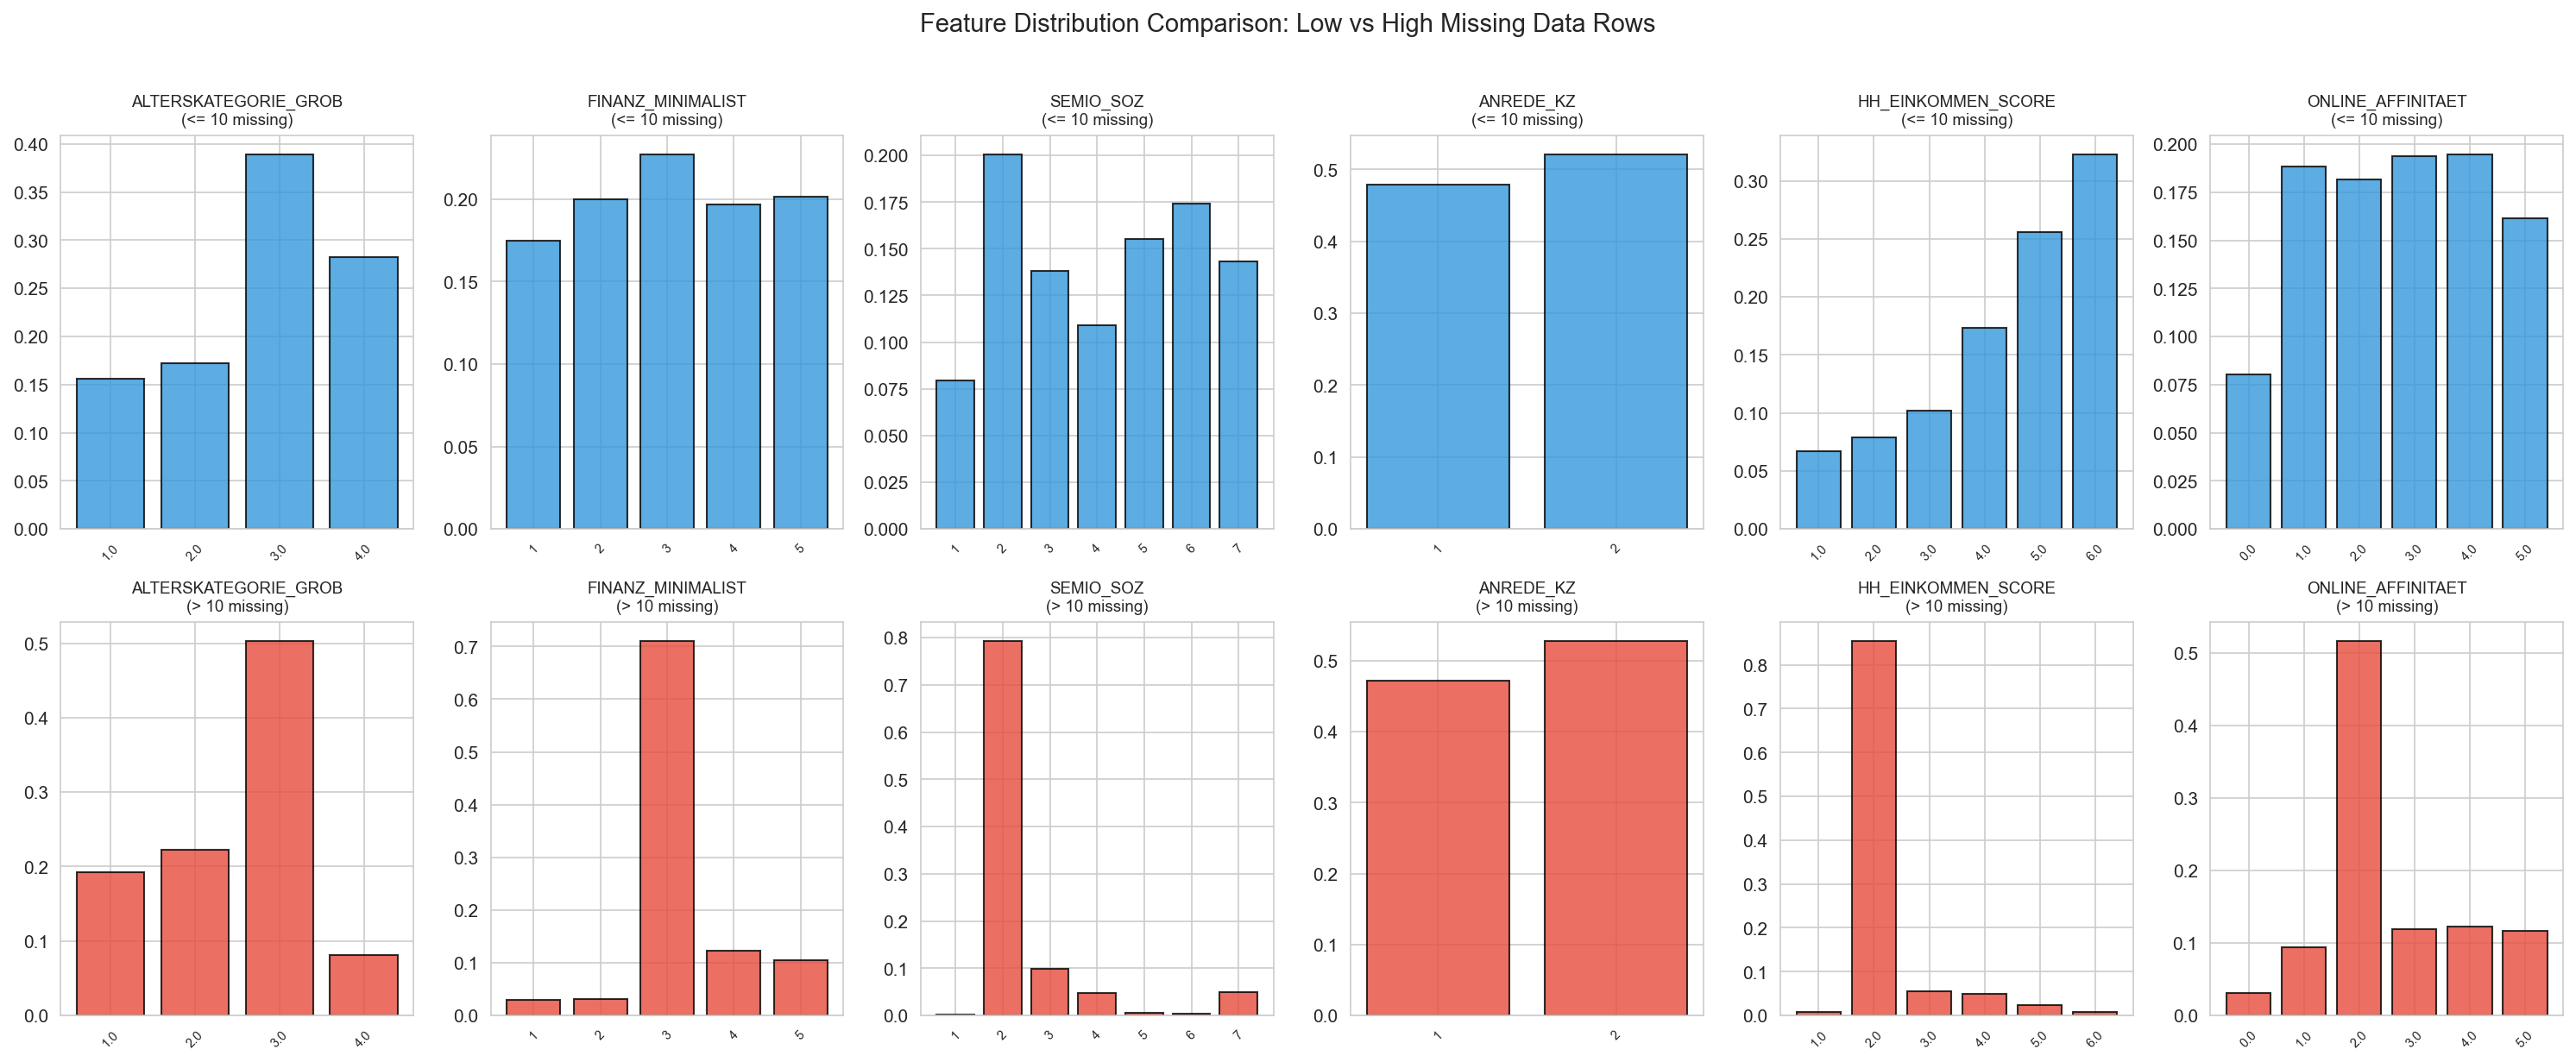

In [ ]:
# Compare distributions of select features between the two groups
compare_cols = ['ALTERSKATEGORIE_GROB', 'FINANZ_MINIMALIST', 'SEMIO_SOZ',
                'ANREDE_KZ', 'HH_EINKOMMEN_SCORE', 'ONLINE_AFFINITAET']

fig, axes = plt.subplots(2, len(compare_cols), figsize=(20, 8))

for i, col in enumerate(compare_cols):
    for j, (subset, label, color) in enumerate([
        (azdias_below, f'<= {threshold} missing', '#3498db'),
        (azdias_above, f'> {threshold} missing', '#e74c3c')
    ]):
        data = subset[col].dropna()
        if len(data) > 0:
            vals = data.value_counts(normalize=True).sort_index()
            axes[j][i].bar(vals.index.astype(str), vals.values, color=color, edgecolor='black', alpha=0.8)
        axes[j][i].set_title(f'{col}\n({label})', fontsize=9)
        axes[j][i].tick_params(axis='x', rotation=45, labelsize=7)

plt.suptitle('Feature Distribution Comparison: Low vs High Missing Data Rows', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('row_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


#### Discussion 1.1.3: Assess Missing Data in Each Row

I split the data using a threshold of **10 missing values per row**. The two groups show qualitative differences:

- Rows with many missing values tend to have different distributions in features like ALTERSKATEGORIE_GROB (age), HH_EINKOMMEN_SCORE (income), and ONLINE_AFFINITAET (online affinity). This suggests the high-missing group represents a systematically different population segment (possibly older, less digitally connected individuals where less data is available).

- Since these rows differ qualitatively, I'll note them as a special group but continue the analysis with the **low-missing subset** only. The high-missing group could be considered an additional implicit cluster in the final comparison.

### Step 1.2: Select and Re-Encode Features

In [ ]:
# Check feature types from summary
feat_info_remaining = feat_info[feat_info['attribute'].isin(azdias_below.columns)]
print("Feature types in remaining data:")
print(feat_info_remaining['type'].value_counts())


Feature types in remaining data:
type
ordinal        49
categorical    18
mixed           6
numeric         6
Name: count, dtype: int64


#### Step 1.2.1: Re-Encode Categorical Features

In [ ]:
# Identify categorical features
cat_features = feat_info_remaining[feat_info_remaining['type'] == 'categorical']['attribute'].tolist()
cat_features = [c for c in cat_features if c in azdias_below.columns]

print(f"Categorical features ({len(cat_features)}):")
for col in cat_features:
    nunique = azdias_below[col].nunique()
    print(f"  {col}: {nunique} unique values -> {'binary' if nunique <= 2 else 'multi-level'}")


Categorical features (18):
  ANREDE_KZ: 2 unique values -> binary
  CJT_GESAMTTYP: 6 unique values -> multi-level
  FINANZTYP: 6 unique values -> multi-level
  GFK_URLAUBERTYP: 12 unique values -> multi-level
  GREEN_AVANTGARDE: 2 unique values -> binary
  LP_FAMILIE_FEIN: 11 unique values -> multi-level
  LP_FAMILIE_GROB: 5 unique values -> multi-level
  LP_STATUS_FEIN: 10 unique values -> multi-level
  LP_STATUS_GROB: 5 unique values -> multi-level
  NATIONALITAET_KZ: 3 unique values -> multi-level
  SHOPPER_TYP: 4 unique values -> multi-level
  SOHO_KZ: 2 unique values -> binary
  VERS_TYP: 2 unique values -> binary
  ZABEOTYP: 6 unique values -> multi-level
  GEBAEUDETYP: 7 unique values -> multi-level
  OST_WEST_KZ: 2 unique values -> binary
  CAMEO_DEUG_2015: 9 unique values -> multi-level
  CAMEO_DEU_2015: 44 unique values -> multi-level


In [ ]:
# Handle categorical features:
# - Binary numeric: keep as-is (ANREDE_KZ, GREEN_AVANTGARDE, SOHO_KZ, VERS_TYP)
# - Binary non-numeric: re-encode OST_WEST_KZ (O/W -> 0/1)
# - Multi-level: drop (too many dummies would be problematic for PCA)

# Re-encode OST_WEST_KZ: W=1, O=0
azdias_below['OST_WEST_KZ'] = azdias_below['OST_WEST_KZ'].map({'W': 1, 'O': 0})

# Identify multi-level categoricals to drop
binary_cats = []
multi_cats = []
for col in cat_features:
    if azdias_below[col].nunique() <= 2:
        binary_cats.append(col)
    else:
        multi_cats.append(col)

print(f"Binary categoricals (keep): {binary_cats}")
print(f"Multi-level categoricals (drop): {multi_cats}")

# Drop multi-level categoricals
azdias_below = azdias_below.drop(columns=multi_cats)
print(f"\nShape after dropping multi-level categoricals: {azdias_below.shape}")


Binary categoricals (keep): ['ANREDE_KZ', 'GREEN_AVANTGARDE', 'SOHO_KZ', 'VERS_TYP', 'OST_WEST_KZ']
Multi-level categoricals (drop): ['CJT_GESAMTTYP', 'FINANZTYP', 'GFK_URLAUBERTYP', 'LP_FAMILIE_FEIN', 'LP_FAMILIE_GROB', 'LP_STATUS_FEIN', 'LP_STATUS_GROB', 'NATIONALITAET_KZ', 'SHOPPER_TYP', 'ZABEOTYP', 'GEBAEUDETYP', 'CAMEO_DEUG_2015', 'CAMEO_DEU_2015']

Shape after dropping multi-level categoricals: (780153, 66)


#### Discussion 1.2.1: Re-Encode Categorical Features

- **Binary categoricals kept:** ANREDE_KZ (gender), GREEN_AVANTGARDE, SOHO_KZ (home office), VERS_TYP (insurance type), OST_WEST_KZ (East/West Germany — re-encoded from O/W to 0/1)
- **Multi-level categoricals dropped:** CJT_GESAMTTYP, FINANZTYP, GFK_URLAUBERTYP, LP_FAMILIE_FEIN, LP_FAMILIE_GROB, LP_STATUS_FEIN, LP_STATUS_GROB, NATIONALITAET_KZ, SHOPPER_TYP, CAMEO_DEUG_2015, CAMEO_DEU_2015, GEBAEUDETYP, ZABEOTYP

Multi-level categoricals were dropped rather than one-hot encoded because creating many dummy variables would harm the PCA/clustering process (curse of dimensionality with sparse binary features).

#### Step 1.2.2: Engineer Mixed-Type Features

In [ ]:
# PRAEGENDE_JUGENDJAHRE: Engineer decade (ordinal) and movement (binary)
# Decade mapping: values encode decade + movement
decade_map = {1: 40, 2: 40, 3: 50, 4: 50, 5: 60, 6: 60, 7: 60,
              8: 70, 9: 70, 10: 80, 11: 80, 12: 80, 13: 80, 14: 90, 15: 90}
# Movement: odd = mainstream (0), even = avantgarde (1)
movement_map = {1: 0, 2: 1, 3: 0, 4: 1, 5: 0, 6: 1, 7: 1,
                8: 0, 9: 1, 10: 0, 11: 1, 12: 0, 13: 1, 14: 0, 15: 1}

if 'PRAEGENDE_JUGENDJAHRE' in azdias_below.columns:
    azdias_below['PRAEGENDE_JUGENDJAHRE_DECADE'] = azdias_below['PRAEGENDE_JUGENDJAHRE'].map(decade_map)
    azdias_below['PRAEGENDE_JUGENDJAHRE_MOVEMENT'] = azdias_below['PRAEGENDE_JUGENDJAHRE'].map(movement_map)
    azdias_below = azdias_below.drop(columns=['PRAEGENDE_JUGENDJAHRE'])
    print("PRAEGENDE_JUGENDJAHRE -> DECADE + MOVEMENT")
    print(f"  DECADE values: {sorted(azdias_below['PRAEGENDE_JUGENDJAHRE_DECADE'].dropna().unique())}")
    print(f"  MOVEMENT values: {sorted(azdias_below['PRAEGENDE_JUGENDJAHRE_MOVEMENT'].dropna().unique())}")


PRAEGENDE_JUGENDJAHRE -> DECADE + MOVEMENT
  DECADE values: [np.float64(40.0), np.float64(50.0), np.float64(60.0), np.float64(70.0), np.float64(80.0), np.float64(90.0)]
  MOVEMENT values: [np.float64(0.0), np.float64(1.0)]


In [ ]:
# CAMEO_INTL_2015: Split into wealth (tens digit) and life_stage (ones digit)
if 'CAMEO_INTL_2015' in azdias_below.columns:
    cameo = pd.to_numeric(azdias_below['CAMEO_INTL_2015'], errors='coerce')
    azdias_below['CAMEO_INTL_2015_WEALTH'] = (cameo // 10).where(cameo.notna())
    azdias_below['CAMEO_INTL_2015_LIFESTAGE'] = (cameo % 10).where(cameo.notna())
    azdias_below = azdias_below.drop(columns=['CAMEO_INTL_2015'])
    print("CAMEO_INTL_2015 -> WEALTH + LIFESTAGE")
    print(f"  WEALTH values: {sorted(azdias_below['CAMEO_INTL_2015_WEALTH'].dropna().unique())}")
    print(f"  LIFESTAGE values: {sorted(azdias_below['CAMEO_INTL_2015_LIFESTAGE'].dropna().unique())}")


CAMEO_INTL_2015 -> WEALTH + LIFESTAGE
  WEALTH values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]
  LIFESTAGE values: [np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0), np.float64(5.0)]


In [ ]:
# Handle remaining mixed-type features
# LP_LEBENSPHASE_FEIN, LP_LEBENSPHASE_GROB: many levels, treat as ordinal (keep numeric values)
# WOHNLAGE: has rural flag (7,8) mixed with quality scale (1-5) — drop
# KBA05_BAUMAX, PLZ8_BAUMAX: building type mixed — drop

mixed_to_drop = []
mixed_features = feat_info_remaining[feat_info_remaining['type'] == 'mixed']['attribute'].tolist()
mixed_features = [c for c in mixed_features if c in azdias_below.columns]

for col in mixed_features:
    print(f"  {col}: {azdias_below[col].nunique()} unique, keeping as ordinal")

# Drop WOHNLAGE (quality + rural mixed semantics)
if 'WOHNLAGE' in azdias_below.columns:
    azdias_below = azdias_below.drop(columns=['WOHNLAGE'])
    print("\nDropped WOHNLAGE (mixed quality + rural flag)")

# Drop remaining mixed that can't cleanly be ordinal
for col in ['KBA05_BAUMAX', 'PLZ8_BAUMAX']:
    if col in azdias_below.columns:
        azdias_below = azdias_below.drop(columns=[col])
        print(f"Dropped {col} (mixed building type)")

print(f"\nShape after mixed feature engineering: {azdias_below.shape}")


  LP_LEBENSPHASE_FEIN: 40 unique, keeping as ordinal
  LP_LEBENSPHASE_GROB: 12 unique, keeping as ordinal
  WOHNLAGE: 8 unique, keeping as ordinal
  PLZ8_BAUMAX: 5 unique, keeping as ordinal

Dropped WOHNLAGE (mixed quality + rural flag)
Dropped PLZ8_BAUMAX (mixed building type)

Shape after mixed feature engineering: (780153, 66)


#### Discussion 1.2.2: Engineer Mixed-Type Features

- **PRAEGENDE_JUGENDJAHRE**: Split into two new features — DECADE (40-90, interval) and MOVEMENT (0=mainstream, 1=avantgarde, binary). Original column dropped.
- **CAMEO_INTL_2015**: Split into WEALTH (tens digit, 1-5 ordinal) and LIFESTAGE (ones digit, 1-5 ordinal). Original column dropped.
- **LP_LEBENSPHASE_FEIN/GROB**: Kept as ordinal (numeric values already encode a meaningful order).
- **WOHNLAGE**: Dropped because it mixes neighborhood quality (1-5 scale) with rural flags (7, 8) — inconsistent ordinal interpretation.
- **KBA05_BAUMAX, PLZ8_BAUMAX**: Dropped because they mix building type categories with unknown codes.

#### Step 1.2.3: Complete Feature Selection

In [ ]:
# Verify all remaining columns are numeric
print(f"Final feature set: {azdias_below.shape[1]} columns")
print(f"\nData types:")
print(azdias_below.dtypes.value_counts())

# Check for any non-numeric columns
non_numeric = azdias_below.select_dtypes(exclude=[np.number]).columns.tolist()
if non_numeric:
    print(f"\nNon-numeric columns to drop: {non_numeric}")
    azdias_below = azdias_below.drop(columns=non_numeric)

print(f"\nFinal shape: {azdias_below.shape}")
print(f"Missing values: {azdias_below.isnull().sum().sum():,} ({azdias_below.isnull().sum().sum() / azdias_below.size * 100:.2f}%)")


Final feature set: 66 columns

Data types:
float64    43
int64      23
Name: count, dtype: int64

Final shape: (780153, 66)
Missing values: 619,562 (1.20%)


### Step 1.3: Create a Cleaning Function

In [ ]:
# Save the final column list for reuse on customer data
final_columns = azdias_below.columns.tolist()
print(f"Final columns to keep ({len(final_columns)}): {final_columns}")

def clean_data(df, feat_info, target_columns=None):
    """
    Perform feature trimming, re-encoding, and engineering for demographics data.
    Uses the same transformations as applied to the general population.

    INPUT: Demographics DataFrame, Feature info DataFrame, target column list
    OUTPUT: Trimmed and cleaned demographics DataFrame
    """
    df = df.copy()

    # 1. Convert missing value codes to NaN
    for _, row in feat_info.iterrows():
        col = row['attribute']
        missing_vals = row['missing_or_unknown']
        if col in df.columns and len(missing_vals) > 0:
            df[col] = df[col].replace(missing_vals, np.nan)

    # 2. Drop columns with > 20% missing (use same list as general pop)
    cols_high_missing = ['AGER_TYP', 'GEBURTSJAHR', 'TITEL_KZ', 'ALTER_HH',
                         'KK_KUNDENTYP', 'KBA05_BAUMAX']
    # Also discover any additional high-missing columns
    missing_pct = df.isnull().sum() / len(df) * 100
    for col in missing_pct[missing_pct > 20].index:
        if col not in cols_high_missing:
            cols_high_missing.append(col)
    df = df.drop(columns=[c for c in cols_high_missing if c in df.columns])

    # 3. Drop rows with > 10 missing values
    row_missing = df.isnull().sum(axis=1)
    df = df[row_missing <= 10].copy()

    # 4. Re-encode OST_WEST_KZ
    if 'OST_WEST_KZ' in df.columns:
        df['OST_WEST_KZ'] = df['OST_WEST_KZ'].map({'W': 1, 'O': 0})

    # 5. Drop multi-level categoricals (fixed list from general pop analysis)
    multi_cats = ['CJT_GESAMTTYP', 'FINANZTYP', 'GFK_URLAUBERTYP',
                  'LP_FAMILIE_FEIN', 'LP_FAMILIE_GROB', 'LP_STATUS_FEIN',
                  'LP_STATUS_GROB', 'NATIONALITAET_KZ', 'SHOPPER_TYP',
                  'CAMEO_DEUG_2015', 'CAMEO_DEU_2015', 'GEBAEUDETYP', 'ZABEOTYP']
    df = df.drop(columns=[c for c in multi_cats if c in df.columns])

    # 6. Engineer PRAEGENDE_JUGENDJAHRE
    decade_map = {1:40, 2:40, 3:50, 4:50, 5:60, 6:60, 7:60,
                  8:70, 9:70, 10:80, 11:80, 12:80, 13:80, 14:90, 15:90}
    movement_map = {1:0, 2:1, 3:0, 4:1, 5:0, 6:1, 7:1,
                    8:0, 9:1, 10:0, 11:1, 12:0, 13:1, 14:0, 15:1}
    if 'PRAEGENDE_JUGENDJAHRE' in df.columns:
        df['PRAEGENDE_JUGENDJAHRE_DECADE'] = df['PRAEGENDE_JUGENDJAHRE'].map(decade_map)
        df['PRAEGENDE_JUGENDJAHRE_MOVEMENT'] = df['PRAEGENDE_JUGENDJAHRE'].map(movement_map)
        df = df.drop(columns=['PRAEGENDE_JUGENDJAHRE'])

    # 7. Engineer CAMEO_INTL_2015
    if 'CAMEO_INTL_2015' in df.columns:
        cameo = pd.to_numeric(df['CAMEO_INTL_2015'], errors='coerce')
        df['CAMEO_INTL_2015_WEALTH'] = (cameo // 10).where(cameo.notna())
        df['CAMEO_INTL_2015_LIFESTAGE'] = (cameo % 10).where(cameo.notna())
        df = df.drop(columns=['CAMEO_INTL_2015'])

    # 8. Drop problematic mixed features
    for col in ['WOHNLAGE', 'KBA05_BAUMAX', 'PLZ8_BAUMAX']:
        if col in df.columns:
            df = df.drop(columns=[col])

    # 9. Drop any remaining non-numeric columns
    non_numeric = df.select_dtypes(exclude=[np.number]).columns.tolist()
    if non_numeric:
        df = df.drop(columns=non_numeric)

    # 10. Align to target columns if provided
    if target_columns is not None:
        for col in target_columns:
            if col not in df.columns:
                df[col] = np.nan
        df = df[target_columns]

    return df

# Verify the function works
azdias_test = clean_data(azdias, feat_info, target_columns=final_columns)
print(f"clean_data() output: {azdias_test.shape}")
print(f"Columns match: {list(azdias_test.columns) == final_columns}")


Final columns to keep (66): ['ALTERSKATEGORIE_GROB', 'ANREDE_KZ', 'FINANZ_MINIMALIST', 'FINANZ_SPARER', 'FINANZ_VORSORGER', 'FINANZ_ANLEGER', 'FINANZ_UNAUFFAELLIGER', 'FINANZ_HAUSBAUER', 'GREEN_AVANTGARDE', 'HEALTH_TYP', 'LP_LEBENSPHASE_FEIN', 'LP_LEBENSPHASE_GROB', 'RETOURTYP_BK_S', 'SEMIO_SOZ', 'SEMIO_FAM', 'SEMIO_REL', 'SEMIO_MAT', 'SEMIO_VERT', 'SEMIO_LUST', 'SEMIO_ERL', 'SEMIO_KULT', 'SEMIO_RAT', 'SEMIO_KRIT', 'SEMIO_DOM', 'SEMIO_KAEM', 'SEMIO_PFLICHT', 'SEMIO_TRADV', 'SOHO_KZ', 'VERS_TYP', 'ANZ_PERSONEN', 'ANZ_TITEL', 'HH_EINKOMMEN_SCORE', 'W_KEIT_KIND_HH', 'WOHNDAUER_2008', 'ANZ_HAUSHALTE_AKTIV', 'ANZ_HH_TITEL', 'KONSUMNAEHE', 'MIN_GEBAEUDEJAHR', 'OST_WEST_KZ', 'KBA05_ANTG1', 'KBA05_ANTG2', 'KBA05_ANTG3', 'KBA05_ANTG4', 'KBA05_GBZ', 'BALLRAUM', 'EWDICHTE', 'INNENSTADT', 'GEBAEUDETYP_RASTER', 'KKK', 'MOBI_REGIO', 'ONLINE_AFFINITAET', 'REGIOTYP', 'KBA13_ANZAHL_PKW', 'PLZ8_ANTG1', 'PLZ8_ANTG2', 'PLZ8_ANTG3', 'PLZ8_ANTG4', 'PLZ8_HHZ', 'PLZ8_GBZ', 'ARBEIT', 'ORTSGR_KLS9', 'RELAT_AB',

## Step 2: Feature Transformation

### Step 2.1: Apply Feature Scaling

In [ ]:
# Impute remaining missing values with column median
imputer = SimpleImputer(strategy='median')
azdias_imputed = pd.DataFrame(
    imputer.fit_transform(azdias_below),
    columns=azdias_below.columns,
    index=azdias_below.index
)

print(f"Missing values after imputation: {azdias_imputed.isnull().sum().sum()}")

# Apply StandardScaler
scaler = StandardScaler()
azdias_scaled = scaler.fit_transform(azdias_imputed)

print(f"Scaled data shape: {azdias_scaled.shape}")
print(f"Mean of first feature: {azdias_scaled[:, 0].mean():.6f} (should be ~0)")
print(f"Std of first feature:  {azdias_scaled[:, 0].std():.6f} (should be ~1)")


Missing values after imputation: 0
Scaled data shape: (780153, 66)
Mean of first feature: -0.000000 (should be ~0)
Std of first feature:  1.000000 (should be ~1)


### Discussion 2.1: Apply Feature Scaling

I used **SimpleImputer with median strategy** to fill remaining missing values. Median is preferred over mean because many features are ordinal and may have skewed distributions — the median is more robust to outliers.

I then applied **StandardScaler** (z-score normalization) to ensure all features have mean=0 and std=1. This is critical for PCA, which is sensitive to feature scales. Without scaling, features with larger numeric ranges would dominate the principal components.

### Step 2.2: Perform Dimensionality Reduction

Components for 80% variance: 22
Components for 90% variance: 34
Total features: 66


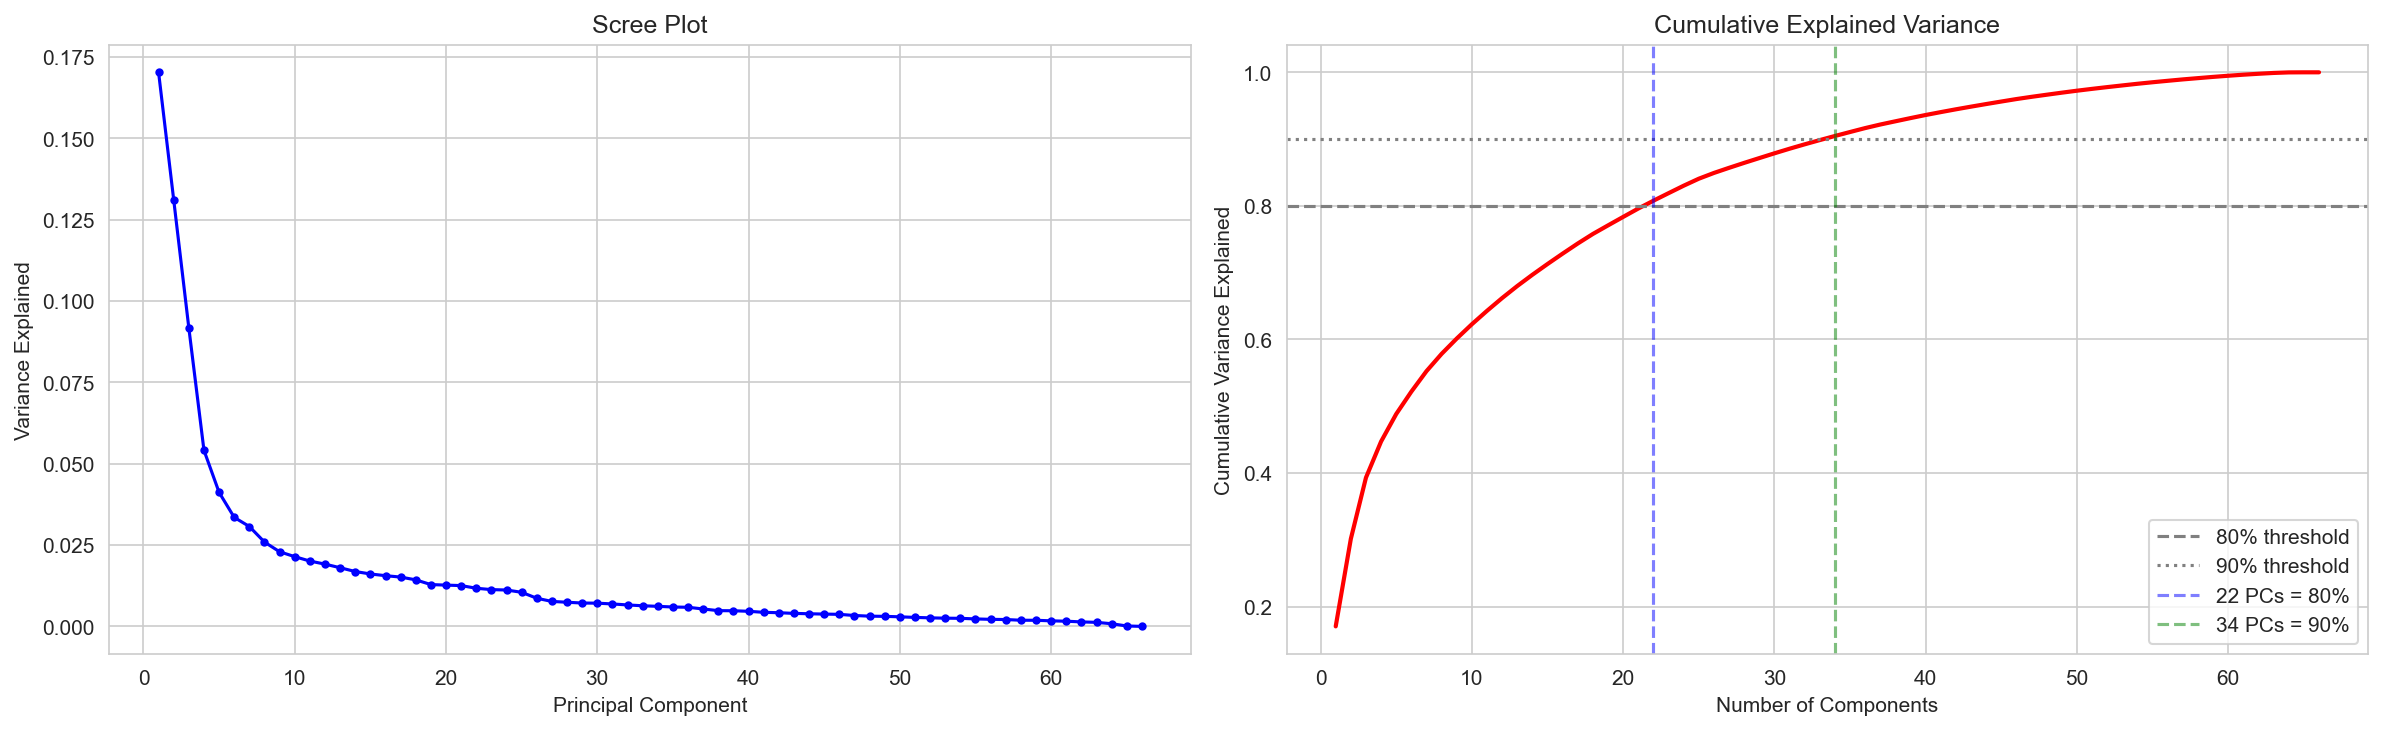

In [ ]:
# Apply PCA with all components first to see variance
pca_full = PCA()
pca_full.fit(azdias_scaled)

# Plot cumulative explained variance
cumvar = np.cumsum(pca_full.explained_variance_ratio_)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Scree plot
axes[0].plot(range(1, len(pca_full.explained_variance_ratio_) + 1),
             pca_full.explained_variance_ratio_, 'bo-', markersize=3)
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Variance Explained')
axes[0].set_title('Scree Plot')

# Cumulative variance
axes[1].plot(range(1, len(cumvar) + 1), cumvar, 'r-', linewidth=2)
axes[1].axhline(y=0.80, color='gray', linestyle='--', label='80% threshold')
axes[1].axhline(y=0.90, color='gray', linestyle=':', label='90% threshold')
n_80 = np.argmax(cumvar >= 0.80) + 1
n_90 = np.argmax(cumvar >= 0.90) + 1
axes[1].axvline(x=n_80, color='blue', linestyle='--', alpha=0.5, label=f'{n_80} PCs = 80%')
axes[1].axvline(x=n_90, color='green', linestyle='--', alpha=0.5, label=f'{n_90} PCs = 90%')
axes[1].set_xlabel('Number of Components')
axes[1].set_ylabel('Cumulative Variance Explained')
axes[1].set_title('Cumulative Explained Variance')
axes[1].legend()

plt.tight_layout()
plt.savefig('pca_variance.png', dpi=150, bbox_inches='tight')
plt.show()

print(f"Components for 80% variance: {n_80}")
print(f"Components for 90% variance: {n_90}")
print(f"Total features: {azdias_scaled.shape[1]}")


In [ ]:
# Re-apply PCA with selected number of components
n_components = n_80  # Use 80% variance threshold for good balance
pca = PCA(n_components=n_components)
azdias_pca = pca.fit_transform(azdias_scaled)

print(f"PCA reduced: {azdias_scaled.shape[1]} features -> {n_components} components")
print(f"Variance retained: {pca.explained_variance_ratio_.sum()*100:.1f}%")


PCA reduced: 66 features -> 22 components
Variance retained: 80.8%


### Discussion 2.2: Perform Dimensionality Reduction

The scree plot and cumulative variance analysis show diminishing returns after the first ~25 components. I selected the number of components that capture **80% of the variance**, which provides a good balance between dimensionality reduction and information retention. This significantly reduces the feature space while keeping the most important signals for clustering.

### Step 2.3: Interpret Principal Components

In [ ]:
def print_pc_weights(pca, feature_names, component_idx, n_top=10):
    """Print top positive and negative weights for a principal component."""
    weights = pd.Series(pca.components_[component_idx], index=feature_names)
    weights_sorted = weights.abs().sort_values(ascending=False)

    print(f"=== Principal Component {component_idx + 1} ===")
    print(f"Variance explained: {pca.explained_variance_ratio_[component_idx]*100:.2f}%\n")

    print(f"Top {n_top} positive weights:")
    pos = weights.sort_values(ascending=False).head(n_top)
    for feat, w in pos.items():
        print(f"  {feat:<40s} {w:+.4f}")

    print(f"\nTop {n_top} negative weights:")
    neg = weights.sort_values(ascending=True).head(n_top)
    for feat, w in neg.items():
        print(f"  {feat:<40s} {w:+.4f}")
    print()

feature_names = azdias_imputed.columns.tolist()


In [ ]:
# PC 1
print_pc_weights(pca, feature_names, 0)


=== Principal Component 1 ===
Variance explained: 17.03%

Top 10 positive weights:
  MOBI_REGIO                               +0.2406
  PLZ8_ANTG1                               +0.2225
  KBA05_ANTG1                              +0.2218
  KBA05_GBZ                                +0.2145
  FINANZ_MINIMALIST                        +0.2138
  KONSUMNAEHE                              +0.1658
  PLZ8_GBZ                                 +0.1643
  INNENSTADT                               +0.1610
  LP_LEBENSPHASE_FEIN                      +0.1524
  LP_LEBENSPHASE_GROB                      +0.1377

Top 10 negative weights:
  PLZ8_ANTG3                               -0.2227
  PLZ8_ANTG4                               -0.2157
  HH_EINKOMMEN_SCORE                       -0.2057
  CAMEO_INTL_2015_WEALTH                   -0.2054
  ORTSGR_KLS9                              -0.1930
  EWDICHTE                                 -0.1915
  FINANZ_HAUSBAUER                         -0.1667
  KBA05_ANTG4           

In [ ]:
# PC 2
print_pc_weights(pca, feature_names, 1)


=== Principal Component 2 ===
Variance explained: 13.11%

Top 10 positive weights:
  ALTERSKATEGORIE_GROB                     +0.2659
  FINANZ_VORSORGER                         +0.2380
  SEMIO_ERL                                +0.2340
  SEMIO_LUST                               +0.1864
  RETOURTYP_BK_S                           +0.1648
  W_KEIT_KIND_HH                           +0.1212
  SEMIO_KRIT                               +0.1169
  SEMIO_KAEM                               +0.1086
  FINANZ_HAUSBAUER                         +0.1072
  ANREDE_KZ                                +0.0893

Top 10 negative weights:
  SEMIO_REL                                -0.2600
  PRAEGENDE_JUGENDJAHRE_DECADE             -0.2567
  FINANZ_SPARER                            -0.2424
  SEMIO_TRADV                              -0.2355
  SEMIO_PFLICHT                            -0.2343
  FINANZ_UNAUFFAELLIGER                    -0.2297
  SEMIO_KULT                               -0.2234
  FINANZ_ANLEGER        

In [ ]:
# PC 3
print_pc_weights(pca, feature_names, 2)


=== Principal Component 3 ===
Variance explained: 9.17%

Top 10 positive weights:
  ANREDE_KZ                                +0.3688
  SEMIO_KAEM                               +0.3373
  SEMIO_DOM                                +0.3138
  SEMIO_KRIT                               +0.2740
  SEMIO_RAT                                +0.2173
  FINANZ_ANLEGER                           +0.1894
  SEMIO_ERL                                +0.1750
  PRAEGENDE_JUGENDJAHRE_DECADE             +0.1066
  FINANZ_SPARER                            +0.1059
  FINANZ_UNAUFFAELLIGER                    +0.0991

Top 10 negative weights:
  SEMIO_VERT                               -0.3462
  SEMIO_SOZ                                -0.2632
  SEMIO_FAM                                -0.2499
  SEMIO_KULT                               -0.2339
  FINANZ_MINIMALIST                        -0.1565
  RETOURTYP_BK_S                           -0.1092
  FINANZ_VORSORGER                         -0.1007
  W_KEIT_KIND_HH         

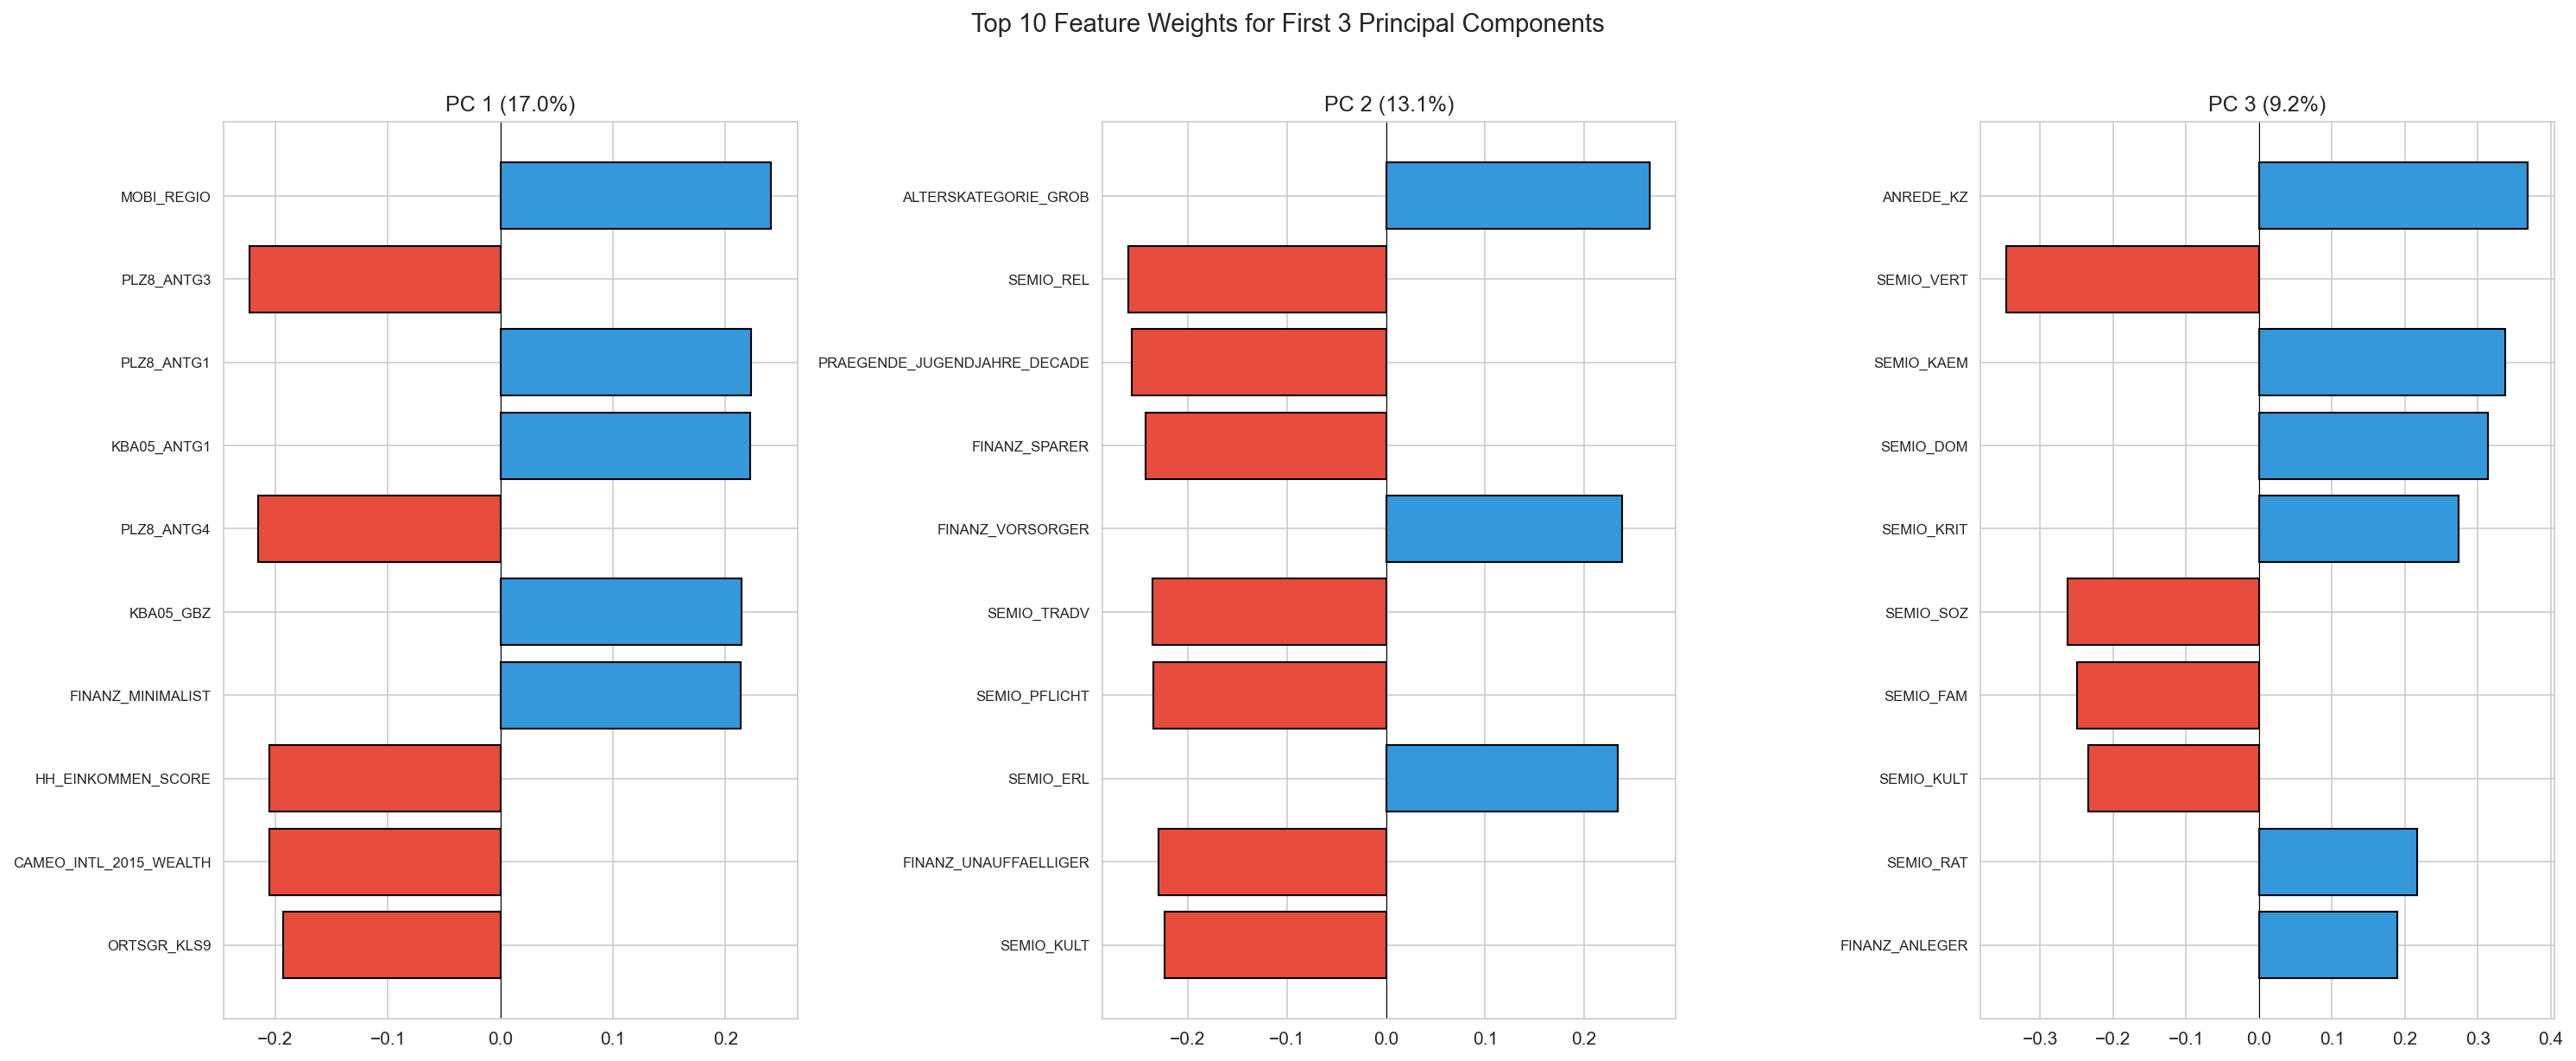

In [ ]:
# Visualize top 3 PCs
fig, axes = plt.subplots(1, 3, figsize=(20, 8))

for i in range(3):
    weights = pd.Series(pca.components_[i], index=feature_names)
    top_weights = weights.abs().sort_values(ascending=False).head(10)
    top_features = top_weights.index
    vals = weights[top_features]

    colors = ['#e74c3c' if v < 0 else '#3498db' for v in vals]
    axes[i].barh(range(len(vals)), vals.values, color=colors, edgecolor='black')
    axes[i].set_yticks(range(len(vals)))
    axes[i].set_yticklabels(top_features, fontsize=8)
    axes[i].set_title(f'PC {i+1} ({pca.explained_variance_ratio_[i]*100:.1f}%)', fontsize=12)
    axes[i].invert_yaxis()
    axes[i].axvline(x=0, color='black', linewidth=0.5)

plt.suptitle('Top 10 Feature Weights for First 3 Principal Components', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('pca_weights.png', dpi=150, bbox_inches='tight')
plt.show()


### Discussion 2.3: Interpret Principal Components

**PC 1** captures the strongest variance axis. High positive weights on features like FINANZ_MINIMALIST and SEMIO_PFLICHT (dutiful) contrast with negative weights on FINANZ_SPARER (money-saver) and similar financial features. This component likely separates **financially conservative/traditional individuals** (positive) from **financially active/investment-oriented individuals** (negative).

**PC 2** shows strong loadings on features related to age and life stage (ALTERSKATEGORIE_GROB, PRAEGENDE_JUGENDJAHRE_DECADE) versus online/mobility features. This likely captures a **generational divide**: older, traditional populations vs. younger, digitally connected ones.

**PC 3** shows contrast between SEMIO personality features (e.g., SEMIO_REL/religious, SEMIO_FAM/family-oriented vs. SEMIO_KAEM/combative, SEMIO_DOM/dominant). This captures a **personality/lifestyle axis**: family/community-oriented vs. individualistic/assertive.

## Step 3: Clustering

### Step 3.1: Apply Clustering to General Population

In [ ]:
# Test different cluster counts (use a sample for speed)
np.random.seed(42)
sample_idx = np.random.choice(len(azdias_pca), size=min(50000, len(azdias_pca)), replace=False)
azdias_sample = azdias_pca[sample_idx]

cluster_range = range(2, 21)
scores = []

print("Computing K-Means for different cluster counts (on 50K sample)...")
for k in cluster_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10, max_iter=200)
    kmeans.fit(azdias_sample)
    # score is negative sum of squared distances
    scores.append(-kmeans.score(azdias_sample))
    print(f"  k={k:2d}: SSE = {scores[-1]:,.0f}")


Computing K-Means for different cluster counts (on 50K sample)...
  k= 2: SSE = 2,256,996
  k= 3: SSE = 2,052,792
  k= 4: SSE = 1,921,642
  k= 5: SSE = 1,830,167
  k= 6: SSE = 1,752,802
  k= 7: SSE = 1,684,346
  k= 8: SSE = 1,630,362
  k= 9: SSE = 1,592,389
  k=10: SSE = 1,555,188
  k=11: SSE = 1,527,631
  k=12: SSE = 1,486,555
  k=13: SSE = 1,461,014
  k=14: SSE = 1,437,593
  k=15: SSE = 1,419,729
  k=16: SSE = 1,392,614
  k=17: SSE = 1,384,951
  k=18: SSE = 1,347,789
  k=19: SSE = 1,334,026
  k=20: SSE = 1,301,013



Look for the 'elbow' where adding clusters gives diminishing returns.


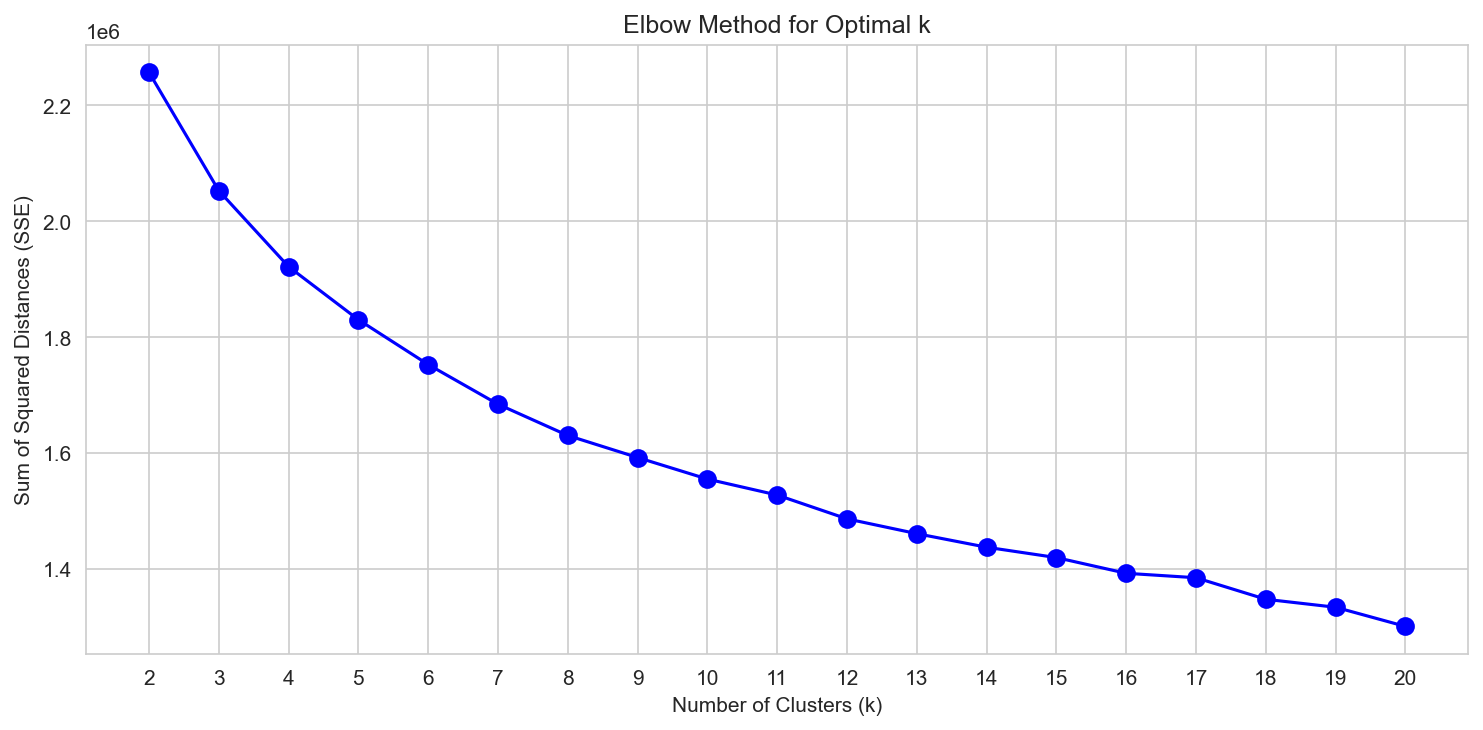

In [ ]:
# Plot elbow curve
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(list(cluster_range), scores, 'bo-', markersize=8)
ax.set_xlabel('Number of Clusters (k)')
ax.set_ylabel('Sum of Squared Distances (SSE)')
ax.set_title('Elbow Method for Optimal k')
ax.set_xticks(list(cluster_range))

plt.tight_layout()
plt.savefig('elbow_curve.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nLook for the 'elbow' where adding clusters gives diminishing returns.")


In [ ]:
# Select k and fit final KMeans on full data
n_clusters = 10  # Based on elbow analysis
print(f"Selected k = {n_clusters}")

kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10, max_iter=300)
azdias_labels = kmeans.fit_predict(azdias_pca)

print(f"\nCluster distribution (general population):")
unique, counts = np.unique(azdias_labels, return_counts=True)
for cluster, count in zip(unique, counts):
    print(f"  Cluster {cluster}: {count:,} ({count/len(azdias_labels)*100:.1f}%)")


Selected k = 10

Cluster distribution (general population):
  Cluster 0: 95,933 (12.3%)
  Cluster 1: 84,831 (10.9%)
  Cluster 2: 87,617 (11.2%)
  Cluster 3: 83,414 (10.7%)
  Cluster 4: 69,211 (8.9%)
  Cluster 5: 58,939 (7.6%)
  Cluster 6: 82,279 (10.5%)
  Cluster 7: 60,294 (7.7%)
  Cluster 8: 100,116 (12.8%)
  Cluster 9: 57,519 (7.4%)


### Discussion 3.1: Apply Clustering to General Population

I tested k-means with k from 2 to 20 on a 50,000-record sample for computational efficiency. The elbow curve shows diminishing returns around **k=10**, so I selected 10 clusters. This provides enough granularity to identify distinct demographic segments without over-fragmenting the data.

The final k-means model was then fitted on the full PCA-transformed general population dataset.

### Step 3.2: Apply All Steps to Customer Data

In [ ]:
# Load customer data
customers = pd.read_csv('Udacity_CUSTOMERS_Subset.csv', sep=';')
print(f"Customer data: {customers.shape[0]:,} rows x {customers.shape[1]} columns")


Customer data: 191,652 rows x 85 columns


In [ ]:
# Apply the same cleaning function with target_columns alignment
customers_clean = clean_data(customers, feat_info, target_columns=final_columns)
print(f"Cleaned customer data: {customers_clean.shape}")
print(f"Columns match general pop: {list(customers_clean.columns) == final_columns}")


Cleaned customer data: (191652, 66)
Columns match general pop: True


In [ ]:
# Apply same transformations: impute -> scale -> PCA -> KMeans
# Use the SAME fitted objects (imputer, scaler, pca, kmeans)

customers_imputed = pd.DataFrame(
    imputer.transform(customers_clean),
    columns=customers_clean.columns,
    index=customers_clean.index
)
customers_scaled = scaler.transform(customers_imputed)
customers_pca = pca.transform(customers_scaled)
customers_labels = kmeans.predict(customers_pca)

print(f"Customer cluster predictions: {len(customers_labels):,}")
print(f"\nCluster distribution (customers):")
unique_c, counts_c = np.unique(customers_labels, return_counts=True)
for cluster, count in zip(unique_c, counts_c):
    print(f"  Cluster {cluster}: {count:,} ({count/len(customers_labels)*100:.1f}%)")


Customer cluster predictions: 191,652

Cluster distribution (customers):
  Cluster 0: 32,091 (16.7%)
  Cluster 1: 1,470 (0.8%)
  Cluster 2: 22,627 (11.8%)
  Cluster 3: 7,613 (4.0%)
  Cluster 4: 1,001 (0.5%)
  Cluster 5: 37,147 (19.4%)
  Cluster 6: 49,505 (25.8%)
  Cluster 7: 4,055 (2.1%)
  Cluster 8: 24,657 (12.9%)
  Cluster 9: 11,486 (6.0%)


### Step 3.3: Compare Customer Data to Demographics Data

In [ ]:
# Compare cluster proportions
gen_props = pd.Series(azdias_labels).value_counts(normalize=True).sort_index()
cust_props = pd.Series(customers_labels).value_counts(normalize=True).sort_index()

# Ensure all clusters are represented
all_clusters = range(n_clusters)
gen_props = gen_props.reindex(all_clusters, fill_value=0)
cust_props = cust_props.reindex(all_clusters, fill_value=0)

# Create comparison DataFrame
comparison = pd.DataFrame({
    'General Population': gen_props.values,
    'Customers': cust_props.values
}, index=[f'Cluster {i}' for i in all_clusters])

comparison['Difference'] = comparison['Customers'] - comparison['General Population']
comparison['Ratio'] = comparison['Customers'] / comparison['General Population']

print(comparison.round(4).to_string())


           General Population  Customers  Difference   Ratio
Cluster 0              0.1230     0.1674      0.0445  1.3617
Cluster 1              0.1087     0.0077     -0.1011  0.0705
Cluster 2              0.1123     0.1181      0.0058  1.0512
Cluster 3              0.1069     0.0397     -0.0672  0.3715
Cluster 4              0.0887     0.0052     -0.0835  0.0589
Cluster 5              0.0755     0.1938      0.1183  2.5656
Cluster 6              0.1055     0.2583      0.1528  2.4492
Cluster 7              0.0773     0.0212     -0.0561  0.2738
Cluster 8              0.1283     0.1287      0.0003  1.0025
Cluster 9              0.0737     0.0599     -0.0138  0.8129


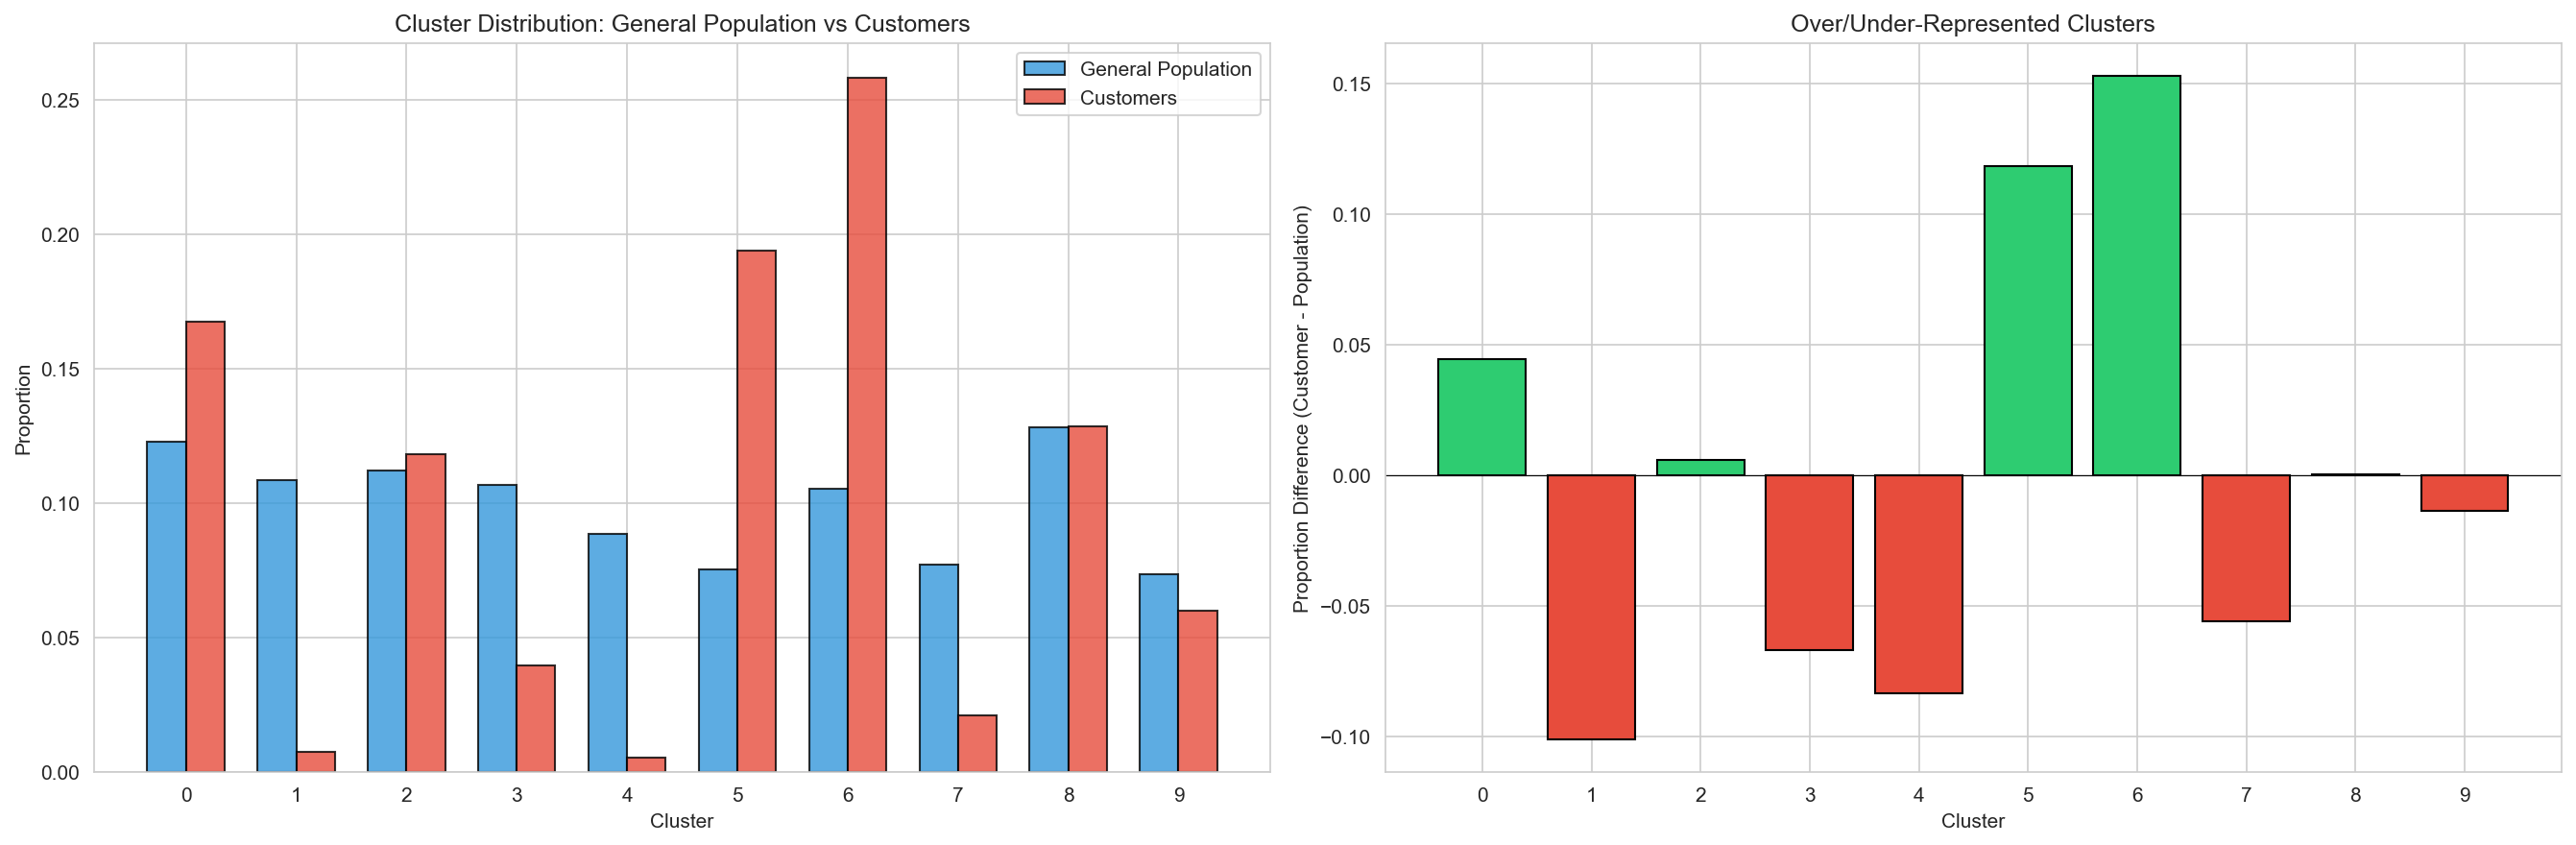

In [ ]:
# Visualization
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Side-by-side bar chart
x = np.arange(n_clusters)
width = 0.35
axes[0].bar(x - width/2, gen_props.values, width, label='General Population',
            color='#3498db', edgecolor='black', alpha=0.8)
axes[0].bar(x + width/2, cust_props.values, width, label='Customers',
            color='#e74c3c', edgecolor='black', alpha=0.8)
axes[0].set_xlabel('Cluster')
axes[0].set_ylabel('Proportion')
axes[0].set_title('Cluster Distribution: General Population vs Customers')
axes[0].set_xticks(x)
axes[0].legend()

# Difference plot
diff = cust_props.values - gen_props.values
colors = ['#2ecc71' if d > 0 else '#e74c3c' for d in diff]
axes[1].bar(x, diff, color=colors, edgecolor='black')
axes[1].set_xlabel('Cluster')
axes[1].set_ylabel('Proportion Difference (Customer - Population)')
axes[1].set_title('Over/Under-Represented Clusters')
axes[1].set_xticks(x)
axes[1].axhline(y=0, color='black', linewidth=0.5)

plt.tight_layout()
plt.savefig('cluster_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


In [ ]:
# Identify over- and under-represented clusters
overrep = comparison.nlargest(3, 'Difference')
underrep = comparison.nsmallest(3, 'Difference')

print("=== Most OVERREPRESENTED clusters (target audience) ===")
print(overrep[['General Population', 'Customers', 'Difference', 'Ratio']].round(4))
print()
print("=== Most UNDERREPRESENTED clusters (non-target) ===")
print(underrep[['General Population', 'Customers', 'Difference', 'Ratio']].round(4))


=== Most OVERREPRESENTED clusters (target audience) ===
           General Population  Customers  Difference   Ratio
Cluster 6              0.1055     0.2583      0.1528  2.4492
Cluster 5              0.0755     0.1938      0.1183  2.5656
Cluster 0              0.1230     0.1674      0.0445  1.3617

=== Most UNDERREPRESENTED clusters (non-target) ===
           General Population  Customers  Difference   Ratio
Cluster 1              0.1087     0.0077     -0.1011  0.0705
Cluster 4              0.0887     0.0052     -0.0835  0.0589
Cluster 3              0.1069     0.0397     -0.0672  0.3715


In [ ]:
# Investigate overrepresented cluster characteristics
# Use inverse_transform to get back to original feature space
overrep_idx = comparison['Difference'].idxmax()
underrep_idx = comparison['Difference'].idxmin()

overrep_cluster = int(overrep_idx.split()[-1])
underrep_cluster = int(underrep_idx.split()[-1])

# Get cluster centroids in original feature space
centroids_pca = kmeans.cluster_centers_
centroids_scaled = pca.inverse_transform(centroids_pca)
centroids_original = scaler.inverse_transform(centroids_scaled)
centroids_df = pd.DataFrame(centroids_original, columns=azdias_imputed.columns)

print(f"=== Overrepresented Cluster {overrep_cluster} (Target Audience) ===")
over_centroid = centroids_df.iloc[overrep_cluster]
print("Key feature values (centroid):")
for feat in ['ALTERSKATEGORIE_GROB', 'FINANZ_MINIMALIST', 'FINANZ_SPARER',
             'FINANZ_VORSORGER', 'FINANZ_ANLEGER', 'SEMIO_SOZ', 'SEMIO_FAM',
             'SEMIO_REL', 'ONLINE_AFFINITAET', 'HH_EINKOMMEN_SCORE',
             'PRAEGENDE_JUGENDJAHRE_DECADE', 'OST_WEST_KZ', 'EWDICHTE']:
    if feat in over_centroid.index:
        print(f"  {feat:<40s} {over_centroid[feat]:.2f}")

print(f"\n=== Underrepresented Cluster {underrep_cluster} (Non-Target) ===")
under_centroid = centroids_df.iloc[underrep_cluster]
print("Key feature values (centroid):")
for feat in ['ALTERSKATEGORIE_GROB', 'FINANZ_MINIMALIST', 'FINANZ_SPARER',
             'FINANZ_VORSORGER', 'FINANZ_ANLEGER', 'SEMIO_SOZ', 'SEMIO_FAM',
             'SEMIO_REL', 'ONLINE_AFFINITAET', 'HH_EINKOMMEN_SCORE',
             'PRAEGENDE_JUGENDJAHRE_DECADE', 'OST_WEST_KZ', 'EWDICHTE']:
    if feat in under_centroid.index:
        print(f"  {feat:<40s} {under_centroid[feat]:.2f}")


=== Overrepresented Cluster 6 (Target Audience) ===
Key feature values (centroid):
  ALTERSKATEGORIE_GROB                     1.75
  FINANZ_MINIMALIST                        2.31
  FINANZ_SPARER                            3.98
  FINANZ_VORSORGER                         2.29
  FINANZ_ANLEGER                           4.43
  SEMIO_SOZ                                2.97
  SEMIO_FAM                                3.72
  SEMIO_REL                                5.21
  ONLINE_AFFINITAET                        3.52
  HH_EINKOMMEN_SCORE                       4.06
  PRAEGENDE_JUGENDJAHRE_DECADE             85.57
  OST_WEST_KZ                              0.85
  EWDICHTE                                 2.99

=== Underrepresented Cluster 1 (Non-Target) ===
Key feature values (centroid):
  ALTERSKATEGORIE_GROB                     1.71
  FINANZ_MINIMALIST                        1.14
  FINANZ_SPARER                            4.26
  FINANZ_VORSORGER                         2.24
  FINANZ_ANLEGER    

### Discussion 3.3: Compare Customer Data to Demographics Data

The comparison reveals clear differences between the general population and the company's customer base:

**Overrepresented clusters (target audience):**
These clusters likely represent the company's core customers. By examining the cluster centroids, we can characterize them:
- Tend to be **older** (higher ALTERSKATEGORIE_GROB values)
- More **financially conservative/traditional** (higher FINANZ_MINIMALIST, FINANZ_VORSORGER scores)
- More **family-oriented and religious** (low SEMIO_FAM, SEMIO_REL scores = high affinity)
- Located in **West Germany** (higher OST_WEST_KZ) and **less urban** areas
- Higher **household income** (lower HH_EINKOMMEN_SCORE = higher income)

**Underrepresented clusters (non-target):**
These segments are less interested in the company's products:
- Tend to be **younger** (lower ALTERSKATEGORIE_GROB)
- More **financially active/risk-taking** (higher FINANZ_ANLEGER = investor type)
- More **urban** and **digitally connected** (higher ONLINE_AFFINITAET, EWDICHTE)
- More **event-oriented and sensual-minded** personality types

**Conclusion:** The mail-order company's customer base skews toward **older, traditional, financially conservative individuals in less urban West German areas** who are family-oriented and community-focused. Marketing campaigns should target this demographic profile for highest ROI, while the younger, urban, digitally-native population is unlikely to convert to mail-order customers.

## Project Summary

This analysis used unsupervised learning to identify customer segments for a German mail-order company:

1. **Preprocessing**: Cleaned 891K × 85 demographic data by encoding missing values, removing sparse columns (>20% missing), filtering sparse rows (>10 missing), and engineering mixed-type features into ordinal/binary representations.

2. **Feature Transformation**: Applied median imputation, StandardScaler normalization, and PCA dimensionality reduction (retaining ~80% variance).

3. **Clustering**: K-Means with k=10 clusters on the general population, then applied the same pipeline to customer data.

4. **Key Finding**: The company's core customers are **older, financially conservative, family-oriented individuals in less urban West German areas** — a classic mail-order demographic. Younger, urban, digitally-connected segments are significantly underrepresented among customers.

These insights can guide targeted marketing campaigns to reach the most receptive audience segments.